# Phần D — Mô hình Gradient Boosting (LightGBM, XGBoost), Tinh chỉnh Siêu tham số & Giải thích TreeSHAP

**Môn học**: CO3135 — *Programming for AI & Data Science* (CSE@HCMUT)  
**Bài toán**: Dự báo phụ tải điện theo giờ tại Tây Ban Nha (2015–2018), chân trời dự báo trước 1 ngày (*day-ahead*, `horizon = 24h`).

### Nguyên tắc tái lập & đồng bộ bàn giao (`docs/HANDOFF_PART_D.md`)
- **Dữ liệu đã sửa lỗi đảo ngày/tháng**: Dùng nguyên vẹn 100% tập chia theo thời gian (`70 / 15 / 15`) từ `src/data_preprocessing.py` (`fix_day_month_swap()`, đã khôi phục `12.672` giờ).
- **Bộ 42 đặc trưng Phần B**: Gọi trực tiếp `make_datasets(FeatureConfig(horizon=24))` từ `src/features.py` (`Calendar: 18`, `Lag / Rolling: 13`, `Weather: 11`), gồm các cờ ngày đặc biệt (`cal_is_special`, `cal_lag1d_is_off`, `cal_lag7d_is_off`) và lag tuần theo giờ đồng hồ DST.
- **Đánh giá dùng chung**: Chấm đủ 7 chỉ số (`MAE, RMSE, MAPE, sMAPE, R2, MaxAE, ME`) qua `src/evaluate.py` (`ResultsLog`), cố định `SEED = 0`.
- **Giao thức không rò rỉ dữ liệu (khớp tuyệt đối Phần C)**:
  1. Bước 1 & 2: Huấn luyện trên `train` (`23.872` giờ), so sánh hàm mất mát và tinh chỉnh **Optuna TPE** theo **Validation MAE** trên `val` (`5.260` giờ) — **khóa hoàn toàn tập `test`**.
  2. Bước 3: Đóng băng cấu hình tốt nhất, huấn luyện lại trên `train + val` (`29.132` giờ) và đánh giá **1 lần duy nhất** trên `test` (`5.260` giờ).
  3. Bước 4: Giải thích bằng **Exact TreeSHAP** trên cả `val` (`train → val`, so sánh công bằng với RF Permutation Phần C) lẫn `test` (`train + val → test`, mô hình cuối).

In [1]:
from __future__ import annotations

import json
import os
import sys
import warnings
from pathlib import Path

os.environ.setdefault("MPLCONFIGDIR", "/tmp/matplotlib")
warnings.filterwarnings("ignore")

ROOT_DIR = Path("..").resolve() if Path("../data/splits").exists() else Path(".").resolve()
if str(ROOT_DIR) not in sys.path:
    sys.path.insert(0, str(ROOT_DIR))

import lightgbm as lgb
import numpy as np
import pandas as pd
import shap
import xgboost as xgb
from IPython.display import Image, display
from scipy.stats import spearmanr

from src.evaluate import ResultsLog, evaluate
from src.features import TARGET, TSO_FORECAST, FeatureConfig, feature_columns, make_datasets
from src.train_boosting import (
    PLOT_DIR,
    RESULTS_DIR,
    SEED,
    _feature_family,
    _fit_lgbm,
    _fit_xgb,
    step2b_optuna_tuning,
    timed_fit,
)

pd.set_option("display.max_columns", 20)
pd.set_option("display.width", 160)
np.random.seed(SEED)

# Tải 42 đặc trưng Phần B (horizon = 24h) trên dữ liệu đã sửa lỗi đảo ngày/tháng
data = make_datasets(FeatureConfig(horizon=24))
train, val, test = data["train"], data["val"], data["test"]
cols = feature_columns(train)

# Kiểm chứng toàn vẹn & không rò rỉ dữ liệu
assert len(cols) == 42, f"Expected 42 features, got {len(cols)}"
assert train["time"].max() < val["time"].min() < test["time"].min(), "Chronological order violated!"
assert TARGET not in cols and TSO_FORECAST not in cols and "time" not in cols
for name, df_part in [("train", train), ("val", val), ("test", test)]:
    assert not df_part[cols].isna().any().any(), f"Found NaNs in {name}"

family_counts = pd.Series([_feature_family(c) for c in cols]).value_counts()
print(f"Repo root : {ROOT_DIR}")
print(f"Splits    : train={len(train):,}h | val={len(val):,}h | test={len(test):,}h (total={len(train)+len(val)+len(test):,}h)")
print(f"Time span : train [{train['time'].min().date()} .. {train['time'].max().date()}]")
print(f"            val   [{val['time'].min().date()} .. {val['time'].max().date()}]")
print(f"            test  [{test['time'].min().date()} .. {test['time'].max().date()}]")
print("\nPhân bố 42 đặc trưng theo 3 họ Phần B:")
print(family_counts.to_string())

Repo root : /home/tiend/P4AI-DS/energy-demand-forecasting
Splits    : train=23,872h | val=5,260h | test=5,260h (total=34,392h)
Time span : train [2015-01-28 .. 2017-10-19]
            val   [2017-10-19 .. 2018-05-26]
            test  [2018-05-26 .. 2018-12-31]

Phân bố 42 đặc trưng theo 3 họ Phần B:
Calendar (18)         18
Lag / Rolling (13)    13
Weather (11)          11


---
## Bước 1 — Mô hình Boosting mặc định (Untuned) & Chẩn đoán Overfitting (`train → val`)

Đo mốc khởi điểm của `LightGBM (default)` và `XGBoost (default)` trên `train → val` (giữ khóa `test`) và so sánh trực tiếp với mốc mạnh nhất của Phần C là **Random Forest** (`Val MAE = 524,9 MW`).

Mốc Random Forest (Phần C) trên Validation: MAE = 524.88 MW


,model,split,MAE,RMSE,MAPE,R2,ME,fit_s
0,LightGBM (default),train,328.216,446.509,1.166,0.990,-0.000,0.530
1,LightGBM (default),val,498.315,743.805,1.719,0.976,-83.438,0.530
2,XGBoost (default),train,213.674,282.788,0.762,0.996,0.002,0.639
3,XGBoost (default),val,540.349,819.928,1.877,0.971,-89.561,0.639


Đường cong học tập (1 → 600 cây, lr=0.1, L2) — chẩn đoán Generalization Gap:


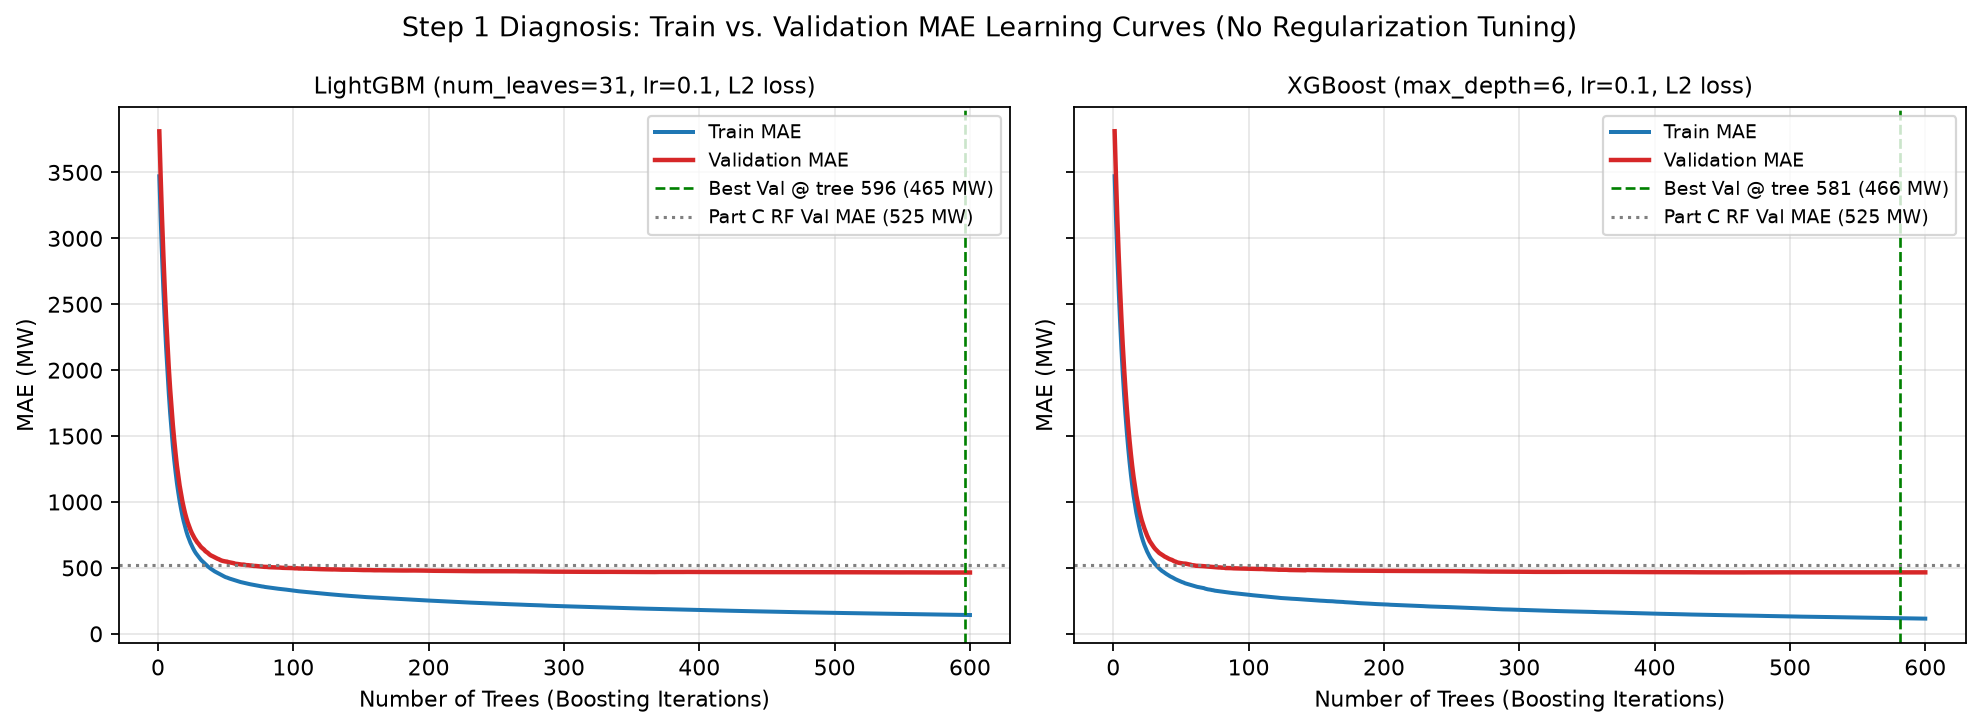

In [2]:
X_tr, y_tr = train[cols], train[TARGET]
X_va, y_va = val[cols], val[TARGET]

log_s1 = ResultsLog()
lgb_def, lgb_s = timed_fit(lgb.LGBMRegressor(random_state=SEED, n_jobs=-1, verbose=-1), X_tr, y_tr)
log_s1.add("LightGBM (default)", "train", y_tr, lgb_def.predict(X_tr), family="boosting_step1", fit_s=lgb_s)
log_s1.add("LightGBM (default)", "val", y_va, lgb_def.predict(X_va), family="boosting_step1", fit_s=lgb_s)

xgb_def, xgb_s = timed_fit(xgb.XGBRegressor(tree_method="hist", random_state=SEED, n_jobs=-1), X_tr, y_tr)
log_s1.add("XGBoost (default)", "train", y_tr, xgb_def.predict(X_tr), family="boosting_step1", fit_s=xgb_s)
log_s1.add("XGBoost (default)", "val", y_va, xgb_def.predict(X_va), family="boosting_step1", fit_s=xgb_s)

df_s1_live = log_s1.to_frame()
df_s1_saved = pd.read_csv(RESULTS_DIR / "d_step1_untuned.csv")
assert np.allclose(df_s1_live["MAE"].to_numpy(), df_s1_saved["MAE"].to_numpy(), atol=1e-2)

df_part_c = pd.read_csv(RESULTS_DIR / "metrics.csv")
rf_val_mae = float(df_part_c.query("model == 'Random Forest' and split == 'val'")["MAE"].iloc[0])
print(f"Mốc Random Forest (Phần C) trên Validation: MAE = {rf_val_mae:,.2f} MW")
display(df_s1_live[["model", "split", "MAE", "RMSE", "MAPE", "R2", "ME", "fit_s"]].round(3))

print("Đường cong học tập (1 → 600 cây, lr=0.1, L2) — chẩn đoán Generalization Gap:")
display(Image(filename=str(PLOT_DIR / "d_step1_learning_curve.png"), width=860))

---
## Bước 2 — Thí nghiệm Hàm mất mát có kiểm soát (2A) & Tinh chỉnh Optuna TPE (2B)

- **2A (Controlled Loss Comparison)**: Cố định cấu trúc cây, so sánh trực tiếp **$L_2$ (MSE)**, **$L_1$ (MAE)** và **Huber ($\delta = 500\text{ MW}$)** cho cả LightGBM và XGBoost (kèm `base_score = median(y_train)` và `max_delta_step = 1500` cho XGBoost Pseudo-Huber).
- **2B (Optuna TPE + Early Stopping)**: Chạy `40 trials` LightGBM (tối ưu đồng thời hàm loss, ngưỡng Huber $\alpha$, `categorical_feature` cho `cal_hour / cal_dayofweek / cal_month` theo gợi ý `HANDOFF_PART_D.md`, độ sâu/số lá và điều chuẩn) và `30 trials` XGBoost theo **Validation MAE**.
- *Lưu ý thực thi*: Mặc định `RUN_OPTUNA_SEARCH = False` nạp siêu tham số đã đóng băng từ `results/d_step2_best_params.json` và **fit trực tiếp lại trên `train → val`** để xác minh tính tái lập nhanh (~20 giây). Đặt `RUN_OPTUNA_SEARCH = True` để chạy lại đủ 70 vòng Optuna từ đầu.

=== 2A. So sánh Hàm mất mát có kiểm soát trên Validation (train -> val) ===


,model_family,loss,best_iteration,train_MAE,val_MAE,gap_MAE,val_RMSE,val_MAPE,val_R2,val_ME
0,LightGBM,L2 (MSE),678,125.194,437.489,312.296,656.603,1.504,0.982,-51.602
1,LightGBM,L1 (MAE),2289,112.651,438.782,326.132,684.215,1.523,0.980,-42.661
2,LightGBM,Huber (delta=500 MW),1814,65.616,432.797,367.181,683.091,1.499,0.980,-50.454
3,XGBoost,L2 (MSE),472,159.940,442.466,282.526,672.839,1.521,0.981,-82.818
4,XGBoost,L1 (MAE),2999,75.863,438.878,363.015,679.994,1.511,0.980,-91.557
5,XGBoost,Huber (delta=500 MW),1334,97.113,446.494,349.381,697.158,1.551,0.979,-83.738



=== 2B. Tái kiểm chứng cấu hình Optuna tối ưu trên Validation (khớp tuyệt đối JSON đã lưu) ===


,model,split,MAE,RMSE,MAPE,sMAPE,R2,MaxAE,ME,fit_s
0,LightGBM (Tuned),val,420.841,641.715,1.447,1.445,0.982,5810.402,-60.615,6.369
1,XGBoost (Tuned),val,429.644,644.143,1.477,1.476,0.982,4970.299,-97.653,10.891


LightGBM categorical_feature: ['cal_hour', 'cal_dayofweek', 'cal_month']
LightGBM best params: {"objective": "regression", "n_estimators": 1171, "learning_rate": 0.0296, "max_depth": 11, "num_leaves": 66, "min_child_samples": 11, "subsample": 0.7216, "subsample_freq": 1, "colsample_bytree": 0.9244, "reg_alpha": 2.1595, "reg_lambda": 1.5705, "random_state": 0, "n_jobs": -1, "verbose": -1}
XGBoost  best params: {"objective": "reg:squarederror", "n_estimators": 2529, "learning_rate": 0.0203, "max_depth": 7, "min_child_weight": 24.8223, "subsample": 0.684, "colsample_bytree": 0.9352, "reg_alpha": 0.0025, "reg_lambda": 25.8061, "tree_method": "hist", "random_state": 0, "n_jobs": -1}


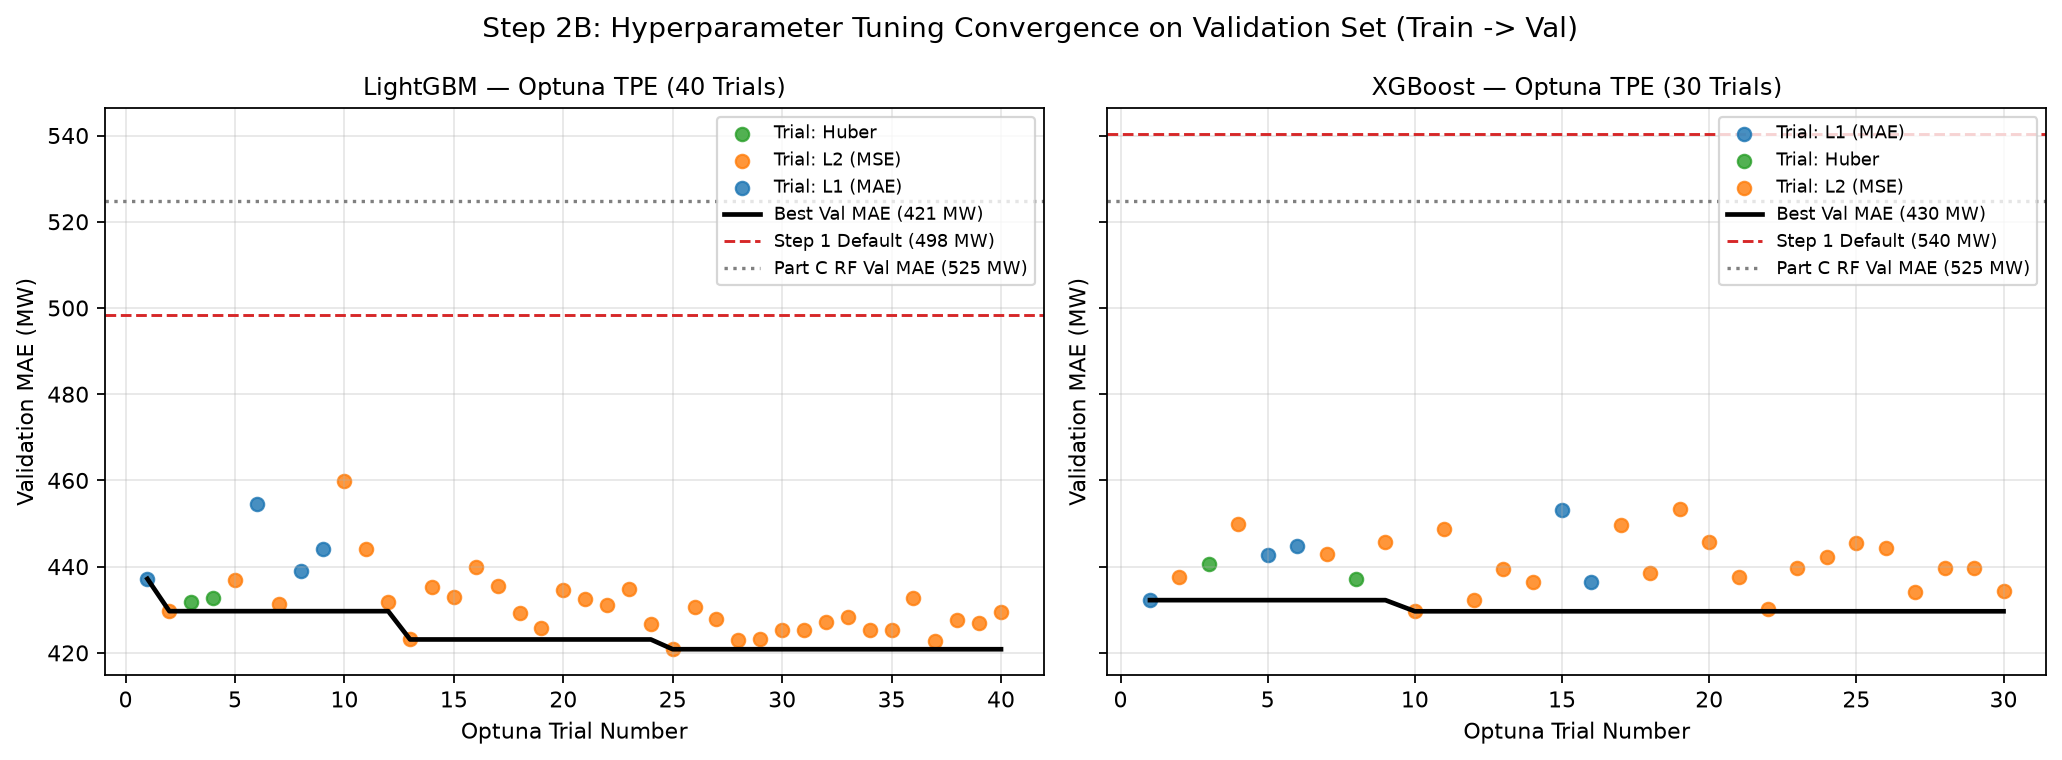

In [3]:
RUN_OPTUNA_SEARCH = False  # Đổi thành True để chạy lại toàn bộ 40+30 Optuna trials

# 2A: Bảng so sánh hàm mất mát có kiểm soát
df_2a = pd.read_csv(RESULTS_DIR / "d_step2_loss_comparison.csv")
print("=== 2A. So sánh Hàm mất mát có kiểm soát trên Validation (train -> val) ===")
display(
    df_2a[["model_family", "loss", "best_iteration", "train_MAE", "val_MAE", "gap_MAE", "val_RMSE", "val_MAPE", "val_R2", "val_ME"]]
    .round(3)
)

# 2B: Nạp (hoặc chạy lại) cấu hình tối ưu và tái kiểm chứng trực tiếp trên train -> val
if RUN_OPTUNA_SEARCH:
    best_lgb_params, best_xgb_params, _, _ = step2b_optuna_tuning(train, val, cols, lgb_trials=40, xgb_trials=30)
saved_s2 = json.loads((RESULTS_DIR / "d_step2_best_params.json").read_text())
best_lgb_params = saved_s2["lgbm_best_params"]
best_lgb_cats = saved_s2.get("lgbm_categorical_features", [])
best_xgb_params = saved_s2["xgb_best_params"]

lgb_val_model, t_lgb_val = _fit_lgbm(best_lgb_params, X_tr, y_tr, cat_cols=best_lgb_cats)
xgb_val_model, t_xgb_val = _fit_xgb(best_xgb_params, X_tr, y_tr)

log_s2 = ResultsLog()
log_s2.add("LightGBM (Tuned)", "val", y_va, lgb_val_model.predict(X_va), fit_s=t_lgb_val)
log_s2.add("XGBoost (Tuned)", "val", y_va, xgb_val_model.predict(X_va), fit_s=t_xgb_val)
df_s2_live = log_s2.to_frame()

assert np.isclose(df_s2_live.loc[0, "MAE"], saved_s2["lgbm_best_val_summary"]["MAE"], atol=1e-2)
assert np.isclose(df_s2_live.loc[1, "MAE"], saved_s2["xgb_best_val_summary"]["MAE"], atol=1e-2)

print("\n=== 2B. Tái kiểm chứng cấu hình Optuna tối ưu trên Validation (khớp tuyệt đối JSON đã lưu) ===")
display(df_s2_live[["model", "split", "MAE", "RMSE", "MAPE", "sMAPE", "R2", "MaxAE", "ME", "fit_s"]].round(3))
print("LightGBM categorical_feature:", best_lgb_cats)
print("LightGBM best params:", json.dumps({k: round(v, 4) if isinstance(v, float) else v for k, v in best_lgb_params.items()}))
print("XGBoost  best params:", json.dumps({k: round(v, 4) if isinstance(v, float) else v for k, v in best_xgb_params.items()}))

display(Image(filename=str(PLOT_DIR / "d_step2_tuning_curves.png"), width=860))

---
## Bước 3 — Đánh giá cuối trên tập `test`, Kiểm định 5 Seeds & So sánh Chân trời (`h = 1` vs `h = 24`)

Đóng băng hoàn toàn siêu tham số Bước 2, huấn luyện lại trên **`train + val` (`29.132` giờ)** và chấm điểm **1 lần duy nhất** trên tập **`test` (`5.260` giờ)** để so sánh công bằng với toàn bộ mô hình Phần C (Baseline, Ridge, Lasso, Random Forest).

=== 3A. Bảng tổng hợp toàn bộ mô hình (Phần C + Phần D) trên tập TEST (5.260 giờ) ===


,model,MAE,RMSE,MAPE,sMAPE,R2,MaxAE,ME,fit_s
1,Naive (t-24h),1804.215,2803.288,6.328,6.395,0.603,12282.000,-1.690,NaN
3,Seasonal naive (t-168h),1233.626,1939.015,4.299,4.220,0.810,16410.000,25.317,NaN
5,Mean of last 4 weeks,1288.902,1853.245,4.499,4.428,0.826,15238.750,-103.935,NaN
7,TSO forecast (reference),252.111,379.123,0.873,0.871,0.993,12207.000,-14.930,NaN
9,Ridge,666.361,885.908,2.384,2.384,0.960,13461.191,-76.448,0.021
11,Lasso,665.097,885.552,2.380,2.379,0.960,13425.685,-77.733,5.220
13,Random Forest,424.996,628.029,1.485,1.478,0.980,11940.100,-30.504,11.460
15,LightGBM (default),447.955,639.771,1.578,1.577,0.979,11957.547,-107.306,2.644
17,XGBoost (default),448.147,635.668,1.580,1.578,0.980,11622.357,-88.152,0.291
19,LightGBM,368.009,530.357,1.286,1.284,0.986,11802.793,-69.132,15.504


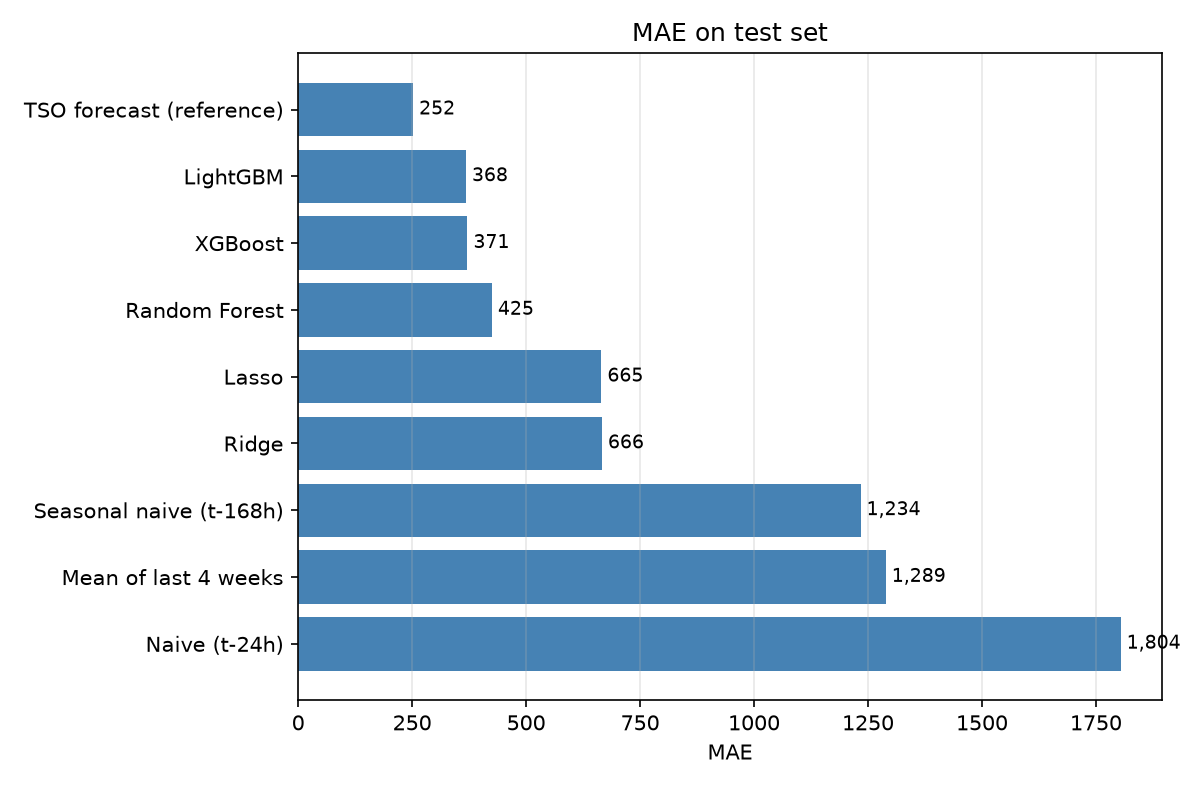

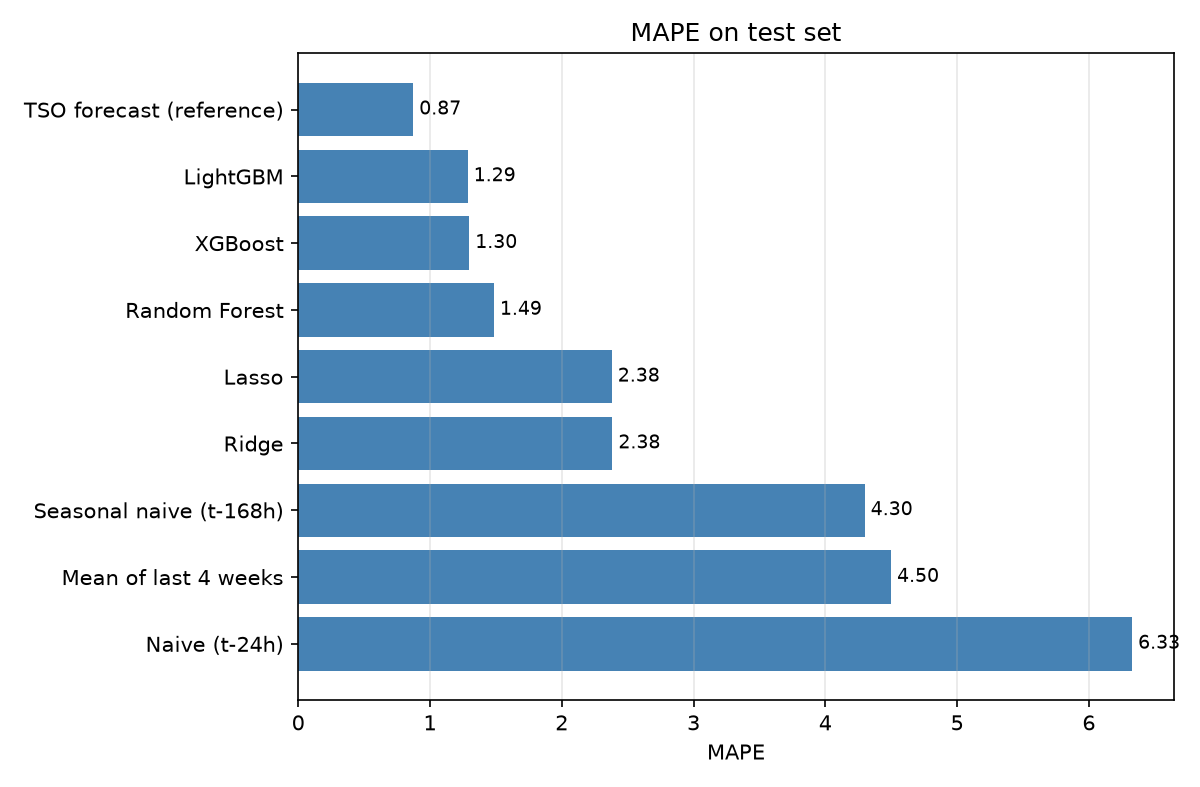

In [4]:
trval = pd.concat([train, val], ignore_index=True)
X_trval, y_trval = trval[cols], trval[TARGET]
X_te, y_te = test[cols], test[TARGET]

# Refit 1 lần duy nhất trên train + val -> test
lgb_final, t_lgb_final = _fit_lgbm(best_lgb_params, X_trval, y_trval, cat_cols=best_lgb_cats)
xgb_final, t_xgb_final = _fit_xgb(best_xgb_params, X_trval, y_trval)

y_pred_lgb_test = lgb_final.predict(X_te)
y_pred_xgb_test = xgb_final.predict(X_te)

log_s3 = ResultsLog()
log_s3.add("LightGBM", "test", y_te, y_pred_lgb_test, family="boosting", fit_s=t_lgb_final)
log_s3.add("XGBoost", "test", y_te, y_pred_xgb_test, family="boosting", fit_s=t_xgb_final)
df_s3_live = log_s3.to_frame()

# Đối chiếu khớp 100% với results/metrics_boosting.csv
df_boost_saved = pd.read_csv(RESULTS_DIR / "metrics_boosting.csv")
for m_name in ["LightGBM", "XGBoost"]:
    live_mae = float(df_s3_live.query("model == @m_name")["MAE"].iloc[0])
    saved_mae = float(df_boost_saved.query("model == @m_name and split == 'test'")["MAE"].iloc[0])
    assert np.isclose(live_mae, saved_mae, atol=1e-2), f"Mismatch for {m_name}: {live_mae} vs {saved_mae}"

print("=== 3A. Bảng tổng hợp toàn bộ mô hình (Phần C + Phần D) trên tập TEST (5.260 giờ) ===")
df_all = pd.read_csv(RESULTS_DIR / "metrics_all.csv")
df_all_test = df_all.query("split == 'test'")[["model", "MAE", "RMSE", "MAPE", "sMAPE", "R2", "MaxAE", "ME", "fit_s"]]
display(df_all_test.round(3))

display(Image(filename=str(PLOT_DIR / "d_step3_mae_test_all.png"), width=780))
display(Image(filename=str(PLOT_DIR / "d_step3_mape_test_all.png"), width=780))

=== 3B. Kiểm định độ ổn định đa seed (seeds = 0..4 trên Test) ===


,model,n_seeds,MAE_mean,MAE_std,RMSE_mean,RMSE_std,MAPE_mean,MAPE_std,R2_mean,R2_std,ME_mean,ME_std
0,LightGBM,5,369.853,3.476,534.139,5.014,1.292,0.012,0.986,0.0,-68.120,2.262
1,XGBoost,5,370.609,3.088,538.317,4.200,1.296,0.011,0.985,0.0,-74.912,2.299



=== 3C. So sánh chân trời dự báo (h = 1h vs h = 24h trên Validation) ===


,horizon_h,model,MAE,RMSE,MAPE
0,1,LightGBM,182.524,262.976,0.623
1,1,XGBoost,195.583,280.969,0.668
2,1,Random Forest,257.507,380.721,0.879
3,1,Ridge,258.905,366.659,0.890
4,1,Naive (t-1h),1142.082,1513.467,3.956
5,24,LightGBM,420.841,641.715,1.447
6,24,XGBoost,429.644,644.143,1.477
7,24,Random Forest,528.456,816.778,1.812
8,24,Ridge,786.405,1051.739,2.727
9,24,Naive (t-24h),1892.964,2897.101,6.543



Biểu đồ dự báo 2 tuần, tuần lễ 12/10, sai số theo giờ & phần dư LightGBM trên Test:


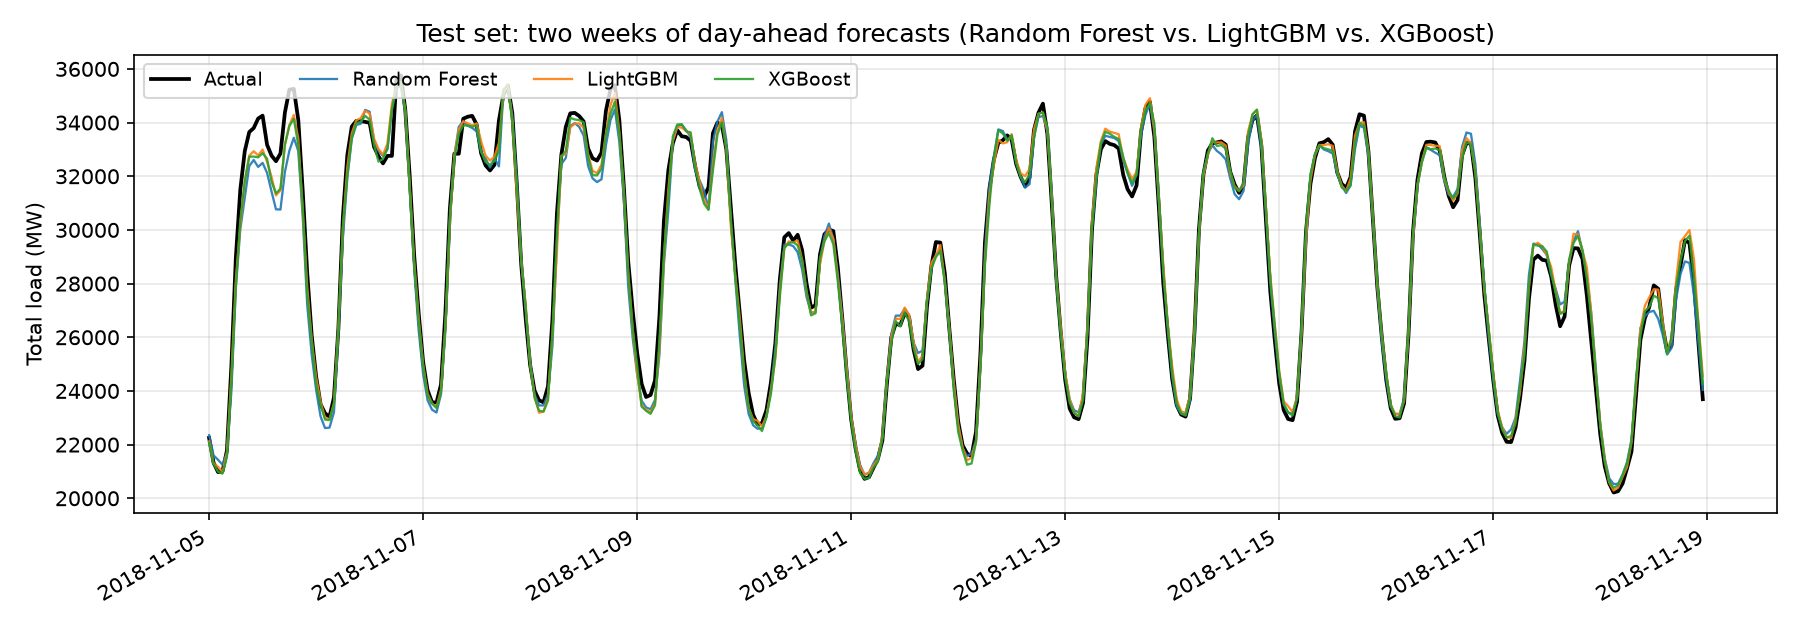

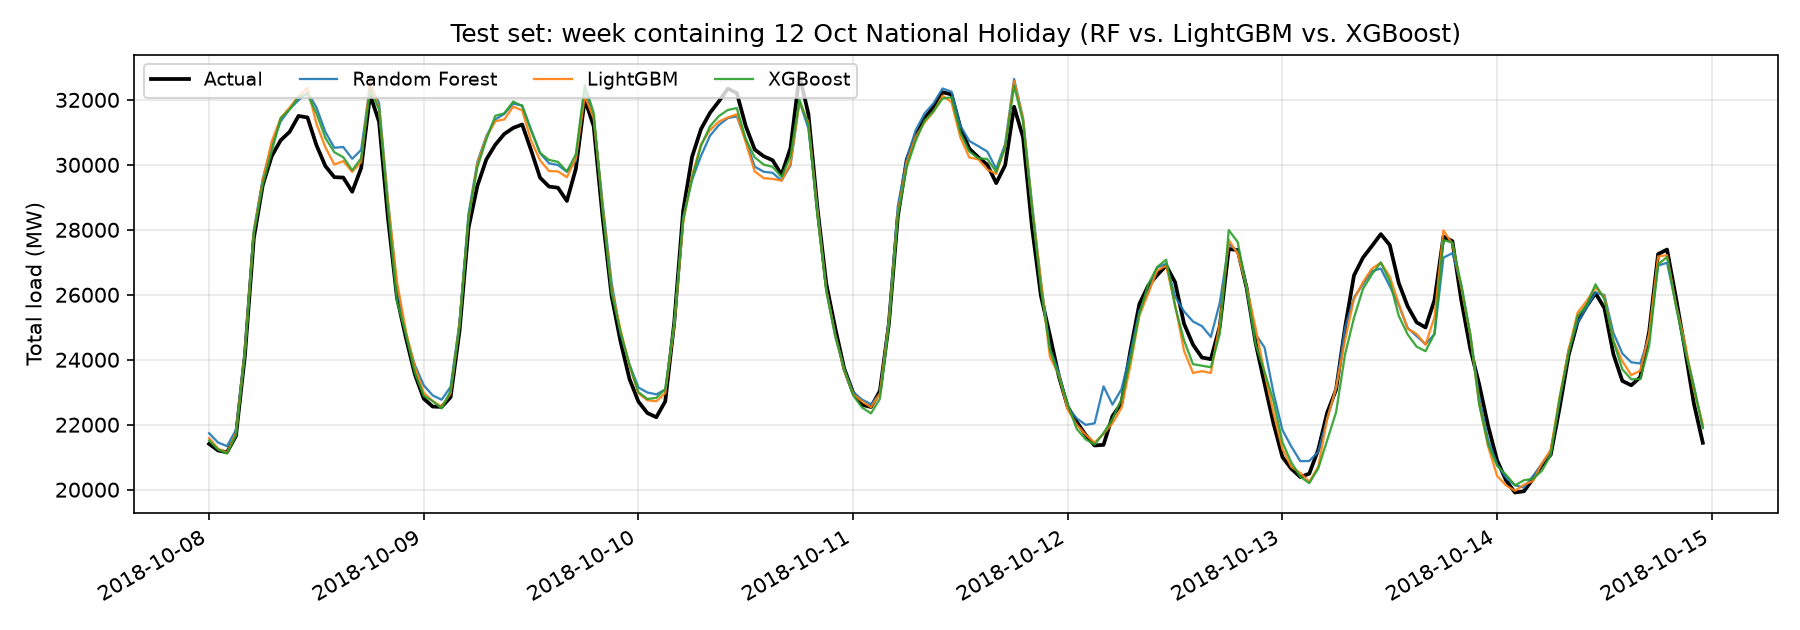

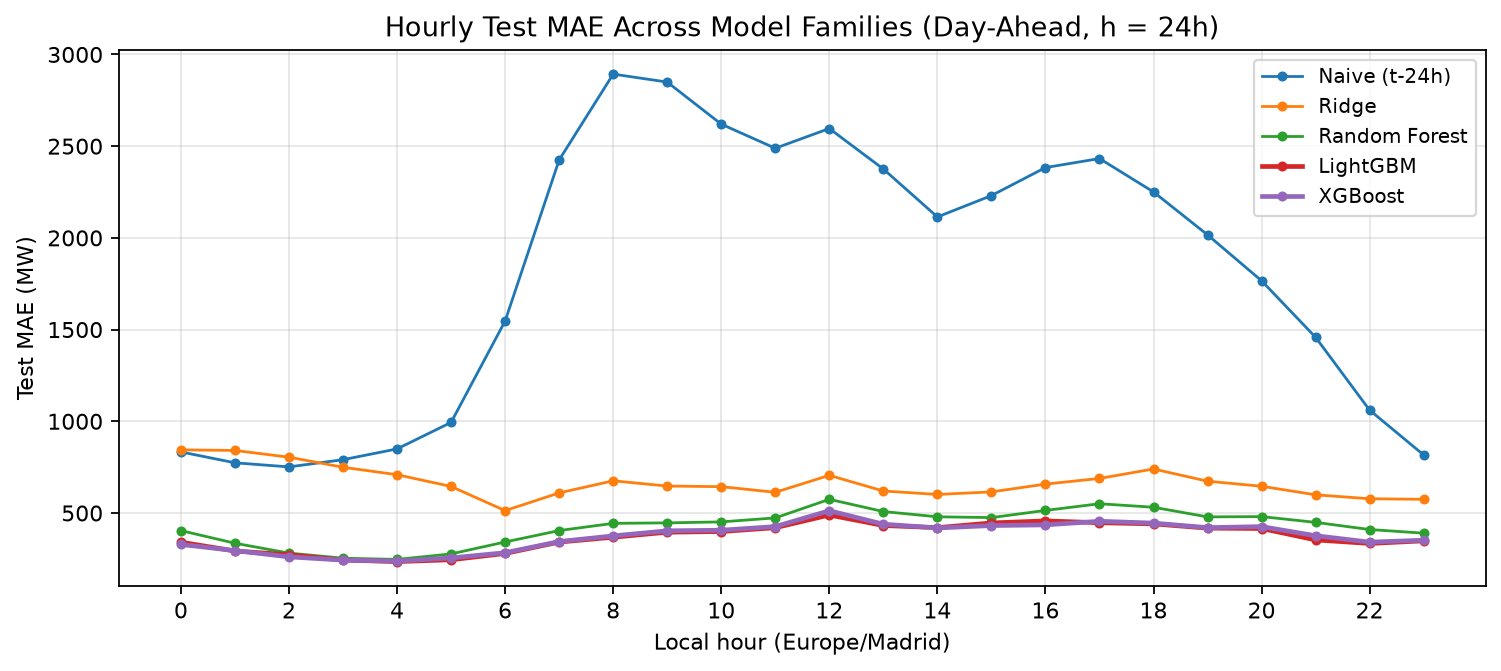

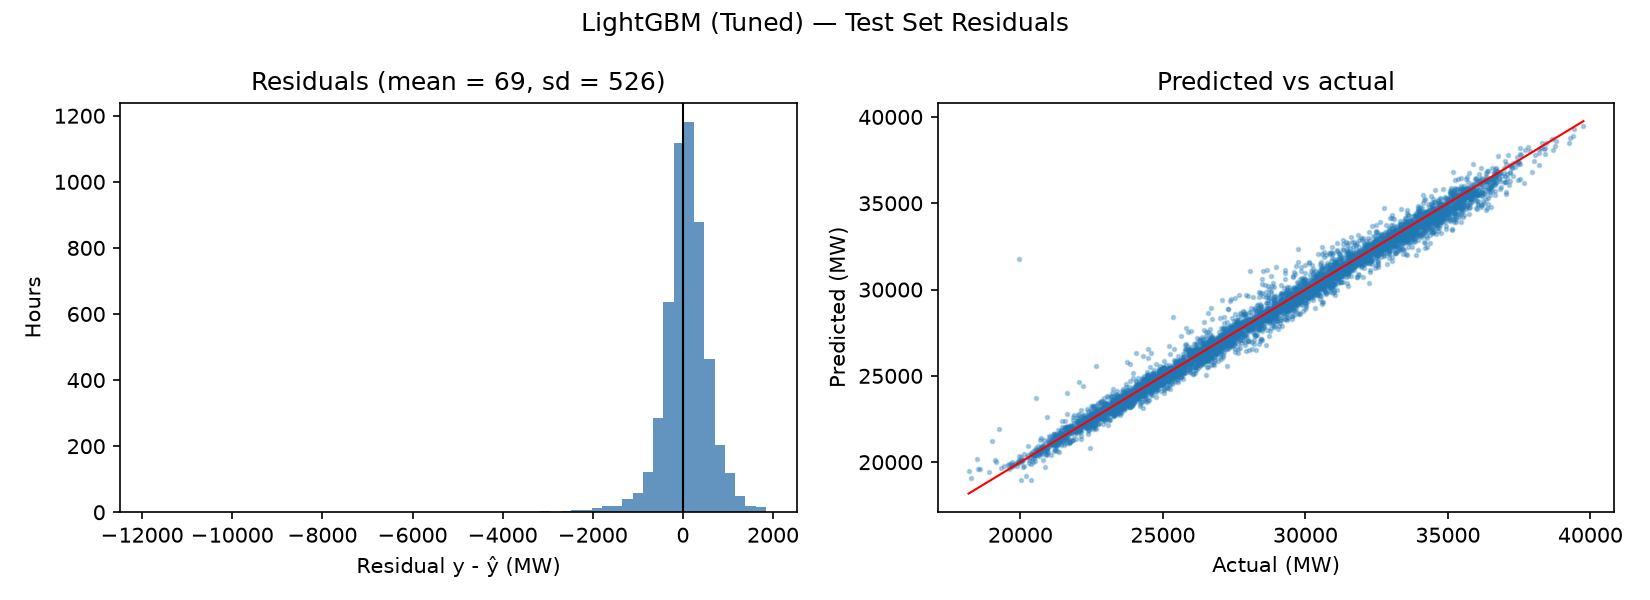

In [5]:
print("=== 3B. Kiểm định độ ổn định đa seed (seeds = 0..4 trên Test) ===")
df_ms = pd.read_csv(RESULTS_DIR / "d_step3_multiseed.csv")
display(df_ms.round(3))

print("\n=== 3C. So sánh chân trời dự báo (h = 1h vs h = 24h trên Validation) ===")
df_hor = pd.read_csv(RESULTS_DIR / "horizon_comparison_all.csv")
display(df_hor.round(3))

print("\nBiểu đồ dự báo 2 tuần, tuần lễ 12/10, sai số theo giờ & phần dư LightGBM trên Test:")
display(Image(filename=str(PLOT_DIR / "d_step3_forecast_2weeks.png"), width=860))
display(Image(filename=str(PLOT_DIR / "d_step3_forecast_holiday.png"), width=860))
display(Image(filename=str(PLOT_DIR / "d_step3_mae_by_hour_all.png"), width=820))
display(Image(filename=str(PLOT_DIR / "d_step3_residuals.png"), width=860))

---
## Bước 4 — Giải thích mô hình bằng Exact TreeSHAP (Phục vụ Mục 6)

Sử dụng **Polynomial Exact TreeSHAP** (`shap.TreeExplainer`, Lundberg et al., 2020) cho cả hai chế độ theo đúng góp ý trong `docs/HANDOFF_PART_D.md`:
1. **So sánh công bằng trên `val` (`train → val`)**: đối chiếu trực tiếp LightGBM TreeSHAP với Random Forest Permutation Importance (`results/feature_importance_rf.csv`).
2. **Giải thích mô hình cuối trên `test` (`train + val → test`)**: Beeswarm Top 15, cộng gộp 3 họ đặc trưng Phần B, đường cong chữ U nhiệt độ và 3 ca Local Waterfall (tách riêng giờ gai cảm biến `2018-06-05 10:00 UTC`).

In [6]:
# 4A: Tính Exact TreeSHAP trực tiếp trên toàn bộ 5.260 giờ tập Test
lgb_explainer = shap.TreeExplainer(lgb_final)
lgb_exp = lgb_explainer(X_te)

# Kiểm chứng tiên đề cộng tính cục bộ (Local Accuracy): y_hat = phi_0 + sum(phi_j)
reconstructed = lgb_exp.base_values + lgb_exp.values.sum(axis=1)
max_additivity_err = float(np.max(np.abs(y_pred_lgb_test - reconstructed)))
assert max_additivity_err < 1e-6, f"Local accuracy violated: {max_additivity_err}"

print(f"Base value (phi_0)                    : {float(lgb_exp.base_values[0]):,.2f} MW")
print(f"Max Local Accuracy Error (LGBM Test)  : {max_additivity_err:.2e} MW  [PASSED < 1e-6 MW]")

# 4B: Bảng xếp hạng Top 15 SHAP (Test & Val) vs. XGBoost SHAP vs. RF Permutation (Phần C)
df_shap = pd.read_csv(RESULTS_DIR / "d_step4_shap_importance.csv")
df_group = pd.read_csv(RESULTS_DIR / "d_step4_shap_by_group.csv")
rho_lgb_xgb = spearmanr(df_shap["lgbm_mean_abs_shap_mw"], df_shap["xgb_mean_abs_shap_mw"]).statistic
rho_lgb_rf_val = spearmanr(df_shap["lgbm_val_mean_abs_shap_mw"], df_shap["perm_mae_increase"]).statistic
print(f"Spearman(LGBM Test SHAP, XGB Test SHAP)        : {rho_lgb_xgb:.4f}")
print(f"Spearman(LGBM Val SHAP, RF Val Perm [công bằng]): {rho_lgb_rf_val:.4f}")

print("\n=== 4B. Top 15 đặc trưng: LightGBM SHAP vs. XGBoost SHAP vs. RF Permutation (Phần C) ===")
show_cols = [
    "lgbm_shap_rank", "feature", "family",
    "lgbm_mean_abs_shap_mw", "lgbm_share_pct",
    "lgbm_val_shap_rank", "xgb_shap_rank", "perm_mae_increase", "rf_perm_rank",
]
display(df_shap[show_cols].head(15).round(2))

print("\n=== Cộng gộp đóng góp SHAP ròng theo 3 họ đặc trưng Phần B (42 biến) ===")
display(df_group.round(2))

Base value (phi_0)                    : 28,635.34 MW
Max Local Accuracy Error (LGBM Test)  : 3.20e-10 MW  [PASSED < 1e-6 MW]
Spearman(LGBM Test SHAP, XGB Test SHAP)        : 0.8357
Spearman(LGBM Val SHAP, RF Val Perm [công bằng]): 0.8201

=== 4B. Top 15 đặc trưng: LightGBM SHAP vs. XGBoost SHAP vs. RF Permutation (Phần C) ===


,lgbm_shap_rank,feature,family,lgbm_mean_abs_shap_mw,lgbm_share_pct,lgbm_val_shap_rank,xgb_shap_rank,perm_mae_increase,rf_perm_rank
0,1,lag_same_hour_4w_mean,Lag / Rolling (13),2021.35,31.85,1,1,915.74,2
1,2,lag_24,Lag / Rolling (13),920.84,14.51,2,2,1392.38,1
2,3,cal_is_offday,Calendar (18),688.24,10.84,4,4,486.22,4
3,4,lag_168,Lag / Rolling (13),684.05,10.78,3,3,773.85,3
4,5,w_temp_roll24,Weather (11),178.22,2.81,5,7,28.42,18
5,6,lag_72,Lag / Rolling (13),174.56,2.75,6,6,130.47,5
6,7,cal_month,Calendar (18),149.62,2.36,10,38,3.99,32
7,8,cal_hour,Calendar (18),124.12,1.96,9,12,58.79,9
8,9,lag_336,Lag / Rolling (13),120.19,1.89,7,20,111.84,6
9,10,w_temp_c_sq,Weather (11),111.16,1.75,8,8,21.65,20



=== Cộng gộp đóng góp SHAP ròng theo 3 họ đặc trưng Phần B (42 biến) ===


,feature_family,n_features,lgbm_mean_abs_net_group_mw,lgbm_sum_indiv_mean_abs_mw,lgbm_sum_indiv_share_pct,xgb_mean_abs_net_group_mw,lgbm_net_group_share_pct
0,Lag / Rolling (13),13,3355.91,4195.26,66.11,3380.96,73.73
1,Calendar (18),18,926.84,1712.04,26.98,913.55,20.36
2,Weather (11),11,268.70,438.98,6.92,264.56,5.90


Beeswarm Top 15 (Test), đối chiếu công bằng trên Val (LGBM SHAP vs. RF Perm), và đường cong chữ U nhiệt độ:


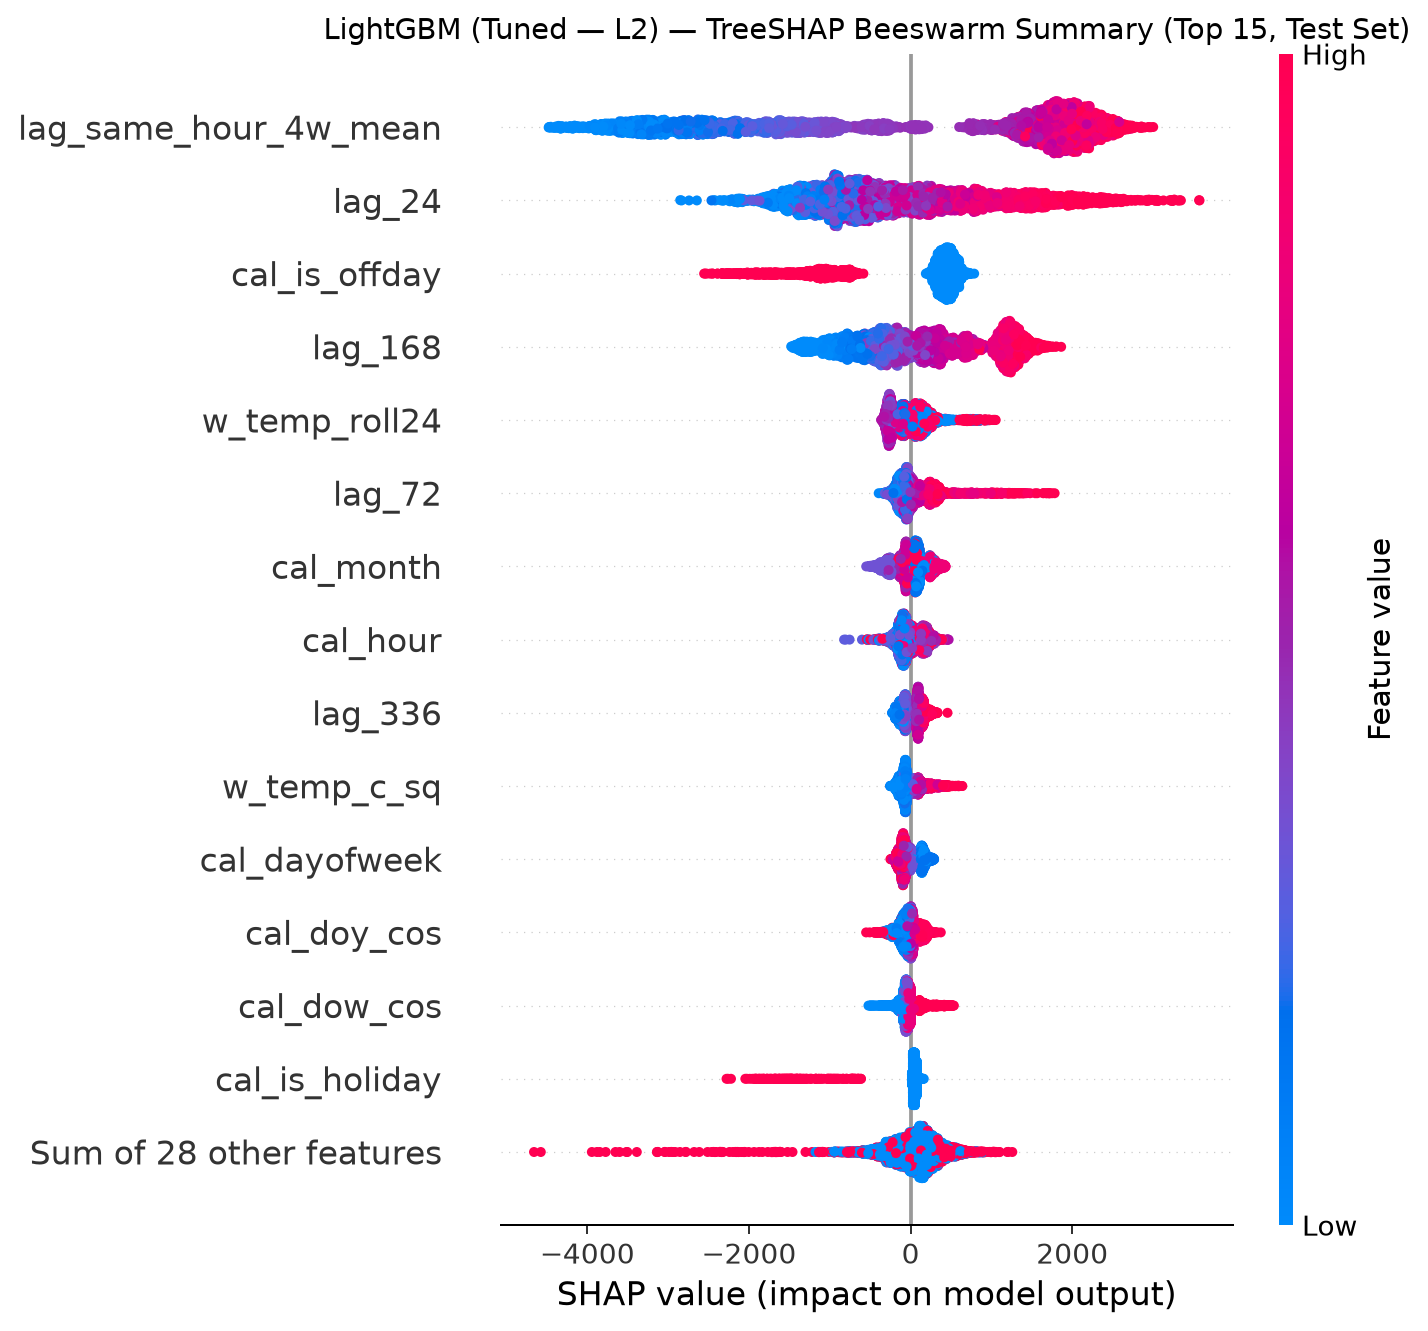

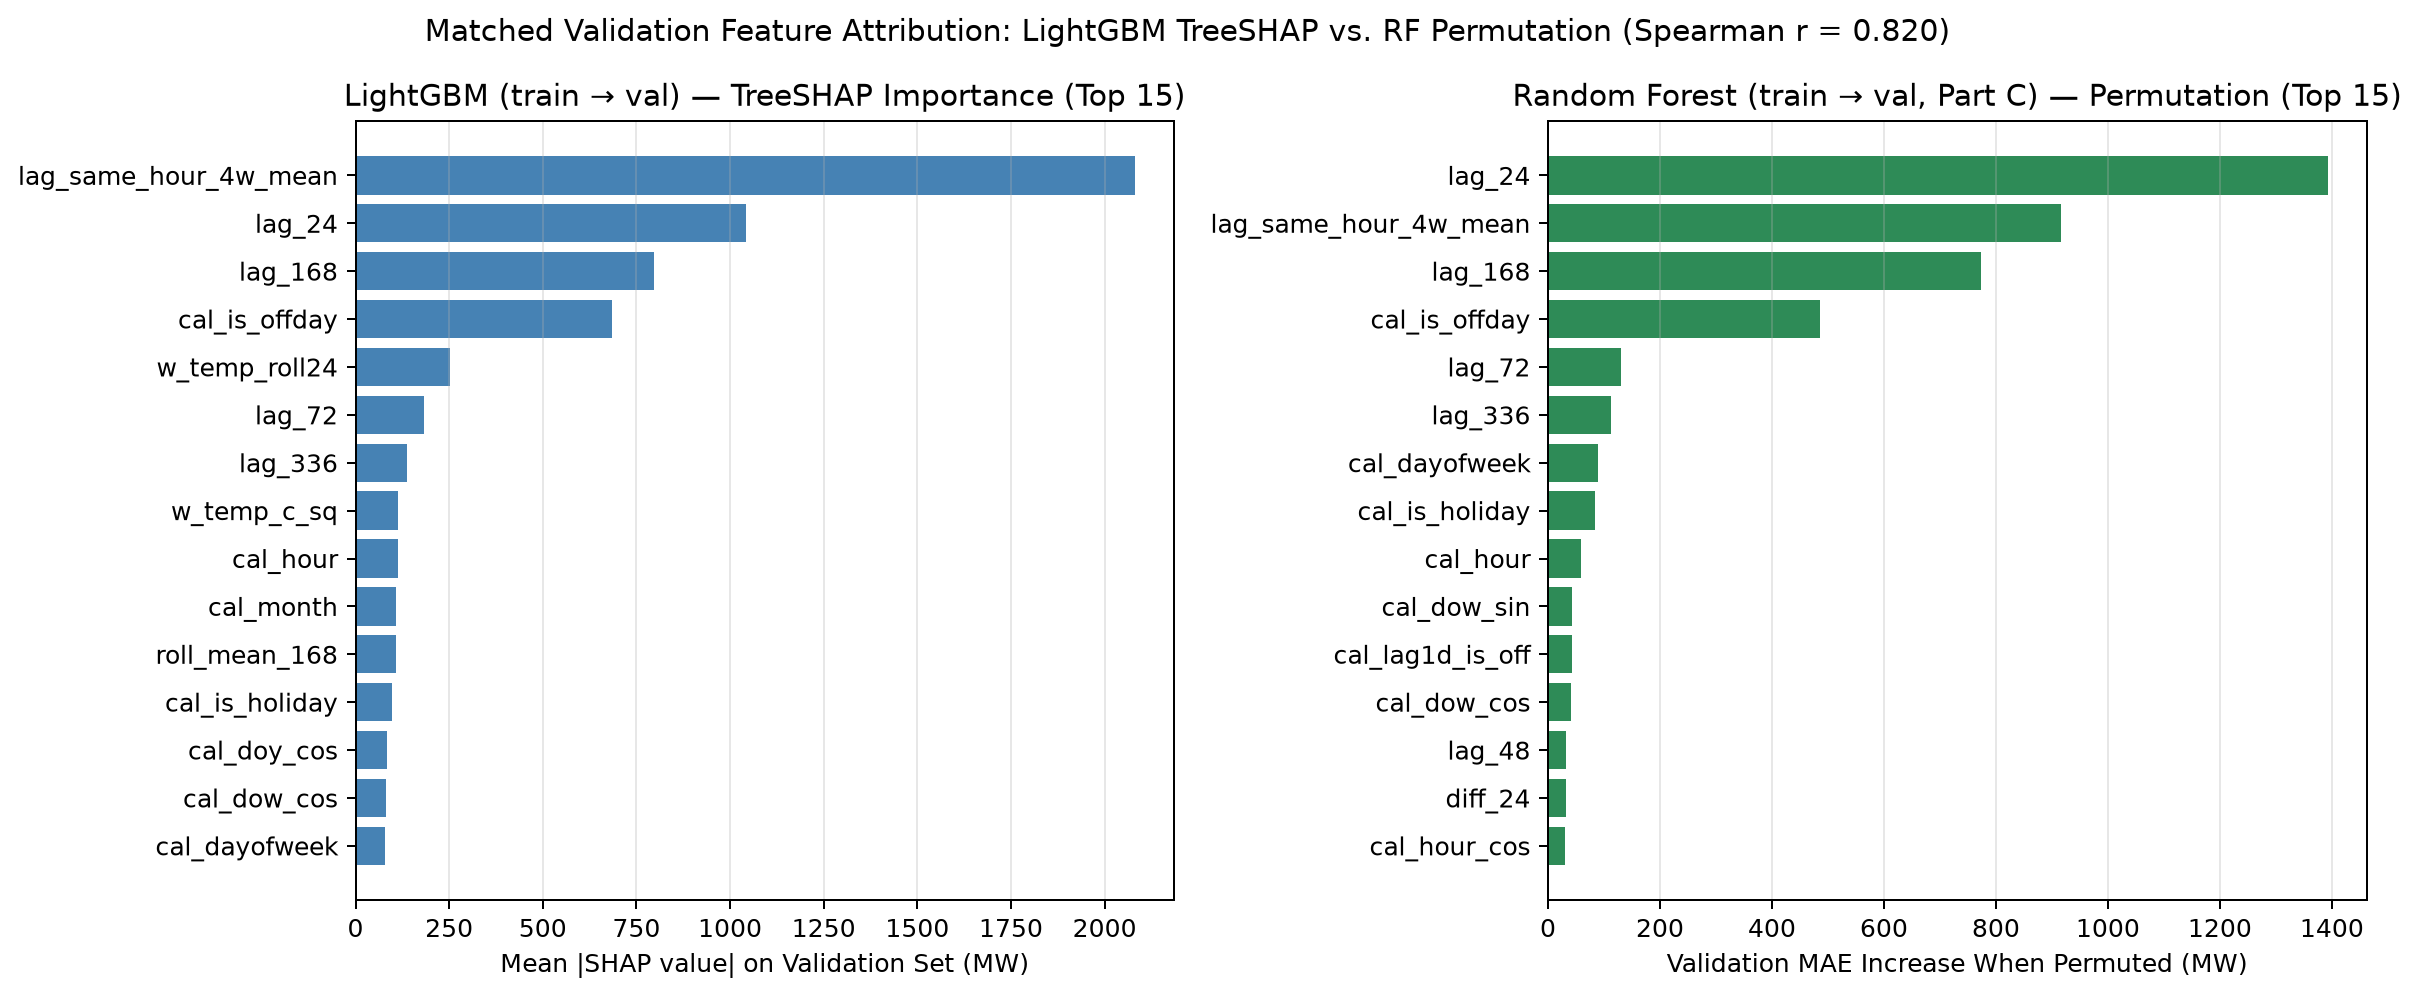

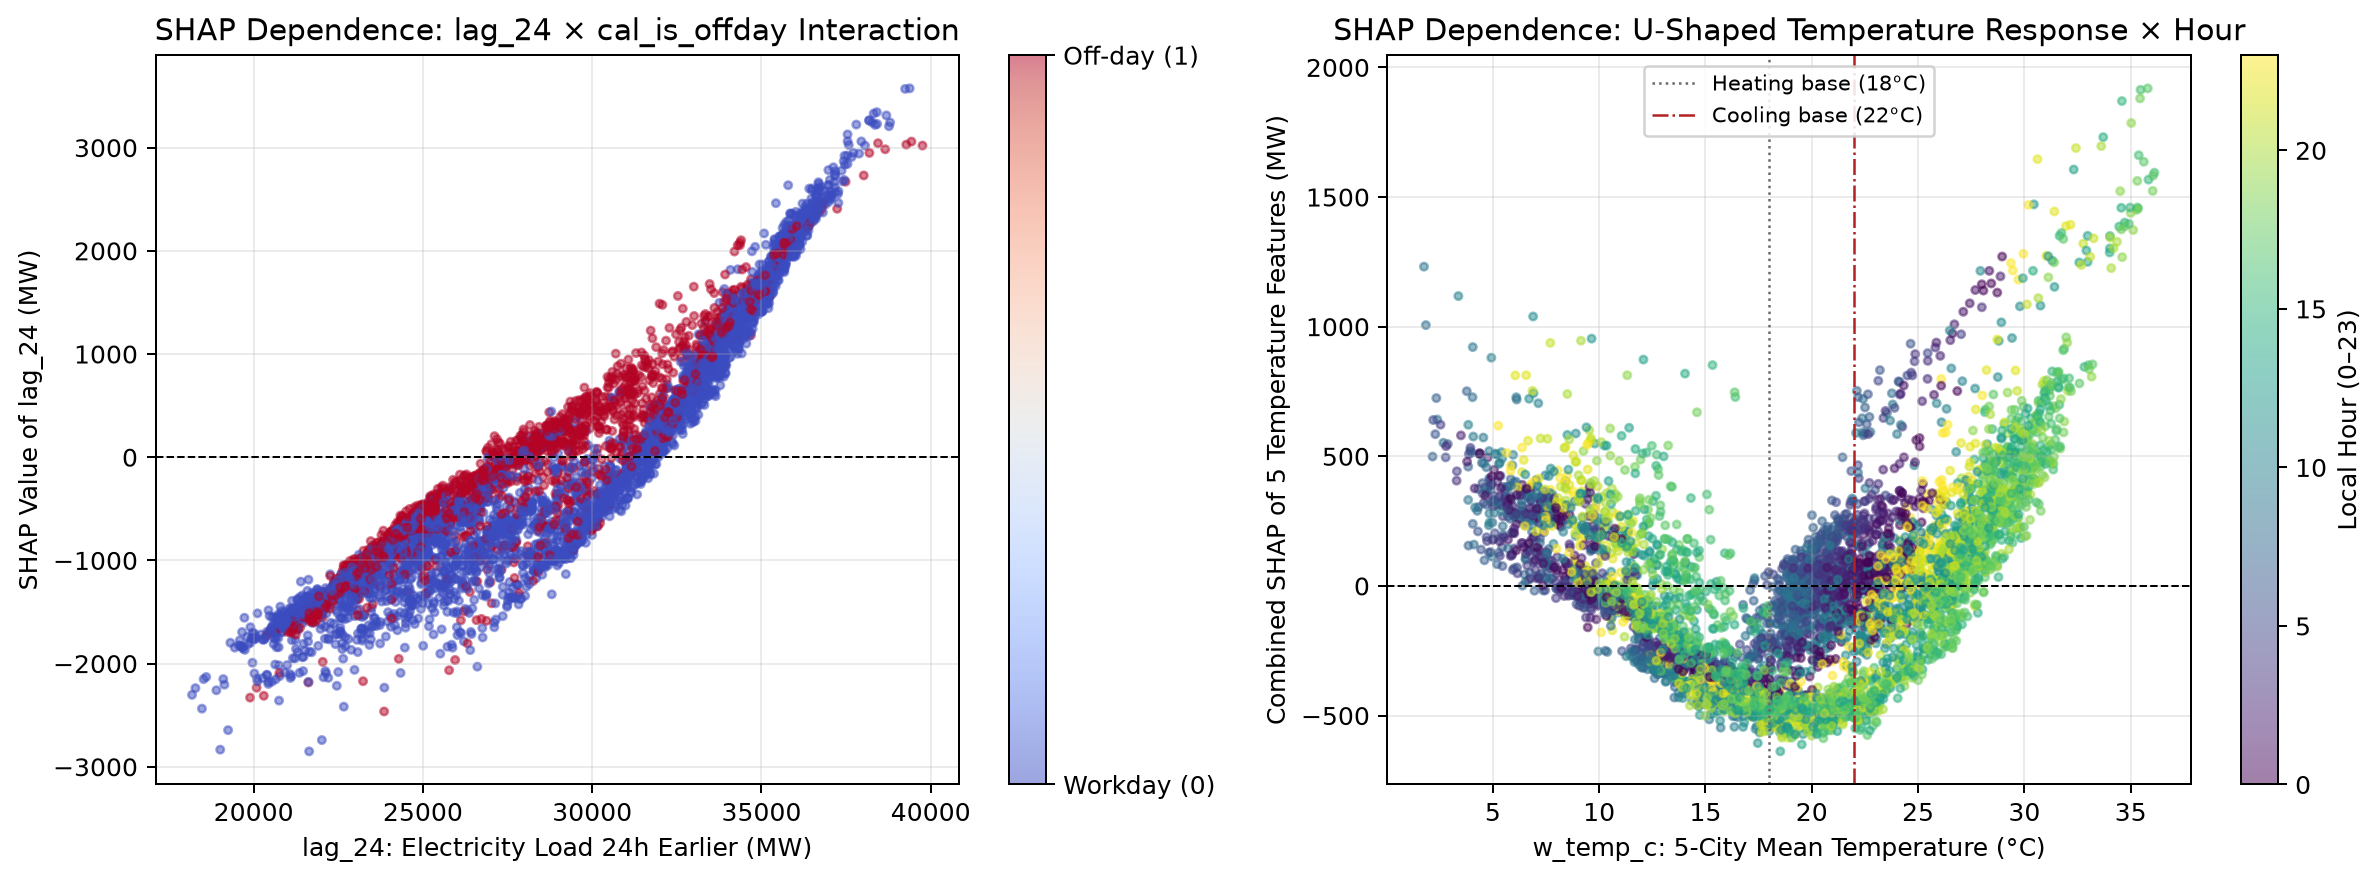

In [7]:
print("Beeswarm Top 15 (Test), đối chiếu công bằng trên Val (LGBM SHAP vs. RF Perm), và đường cong chữ U nhiệt độ:")
display(Image(filename=str(PLOT_DIR / "d_step4_shap_beeswarm.png"), width=780))
display(Image(filename=str(PLOT_DIR / "d_step4_shap_vs_rf.png"), width=880))
display(Image(filename=str(PLOT_DIR / "d_step4_shap_dependence.png"), width=880))

=== 4D. Các tình huống giải thích cục bộ trên tập Test (gồm ghi chú giờ gai cảm biến 05/06/2018) ===


,case,local_time,actual_mw,pred_mw,residual_y_minus_yhat_mw,top_5_shap_drivers
0,peak,2018-08-03 13:00 CEST (Fri),39756.0,39457.331256,298.668744,lag_24=39378.0 (+3575 MW); lag_same_hour_4w_me...
1,holiday,2018-10-12 12:00 CEST (Fri),26606.0,26742.513549,-136.513549,cal_is_offday=1.0 (-2133 MW); cal_is_holiday=1...
2,worst_error,2018-12-25 09:00 CET (Tue),20540.0,23745.855737,-3205.855737,cal_is_offday=1.0 (-2542 MW); cal_is_holiday=1...
3,sensor_glitch,2018-06-05 12:00 CEST (Tue),19964.0,31766.793193,-11802.793193,lag_same_hour_4w_mean=32052.8 (+1690 MW); lag_...


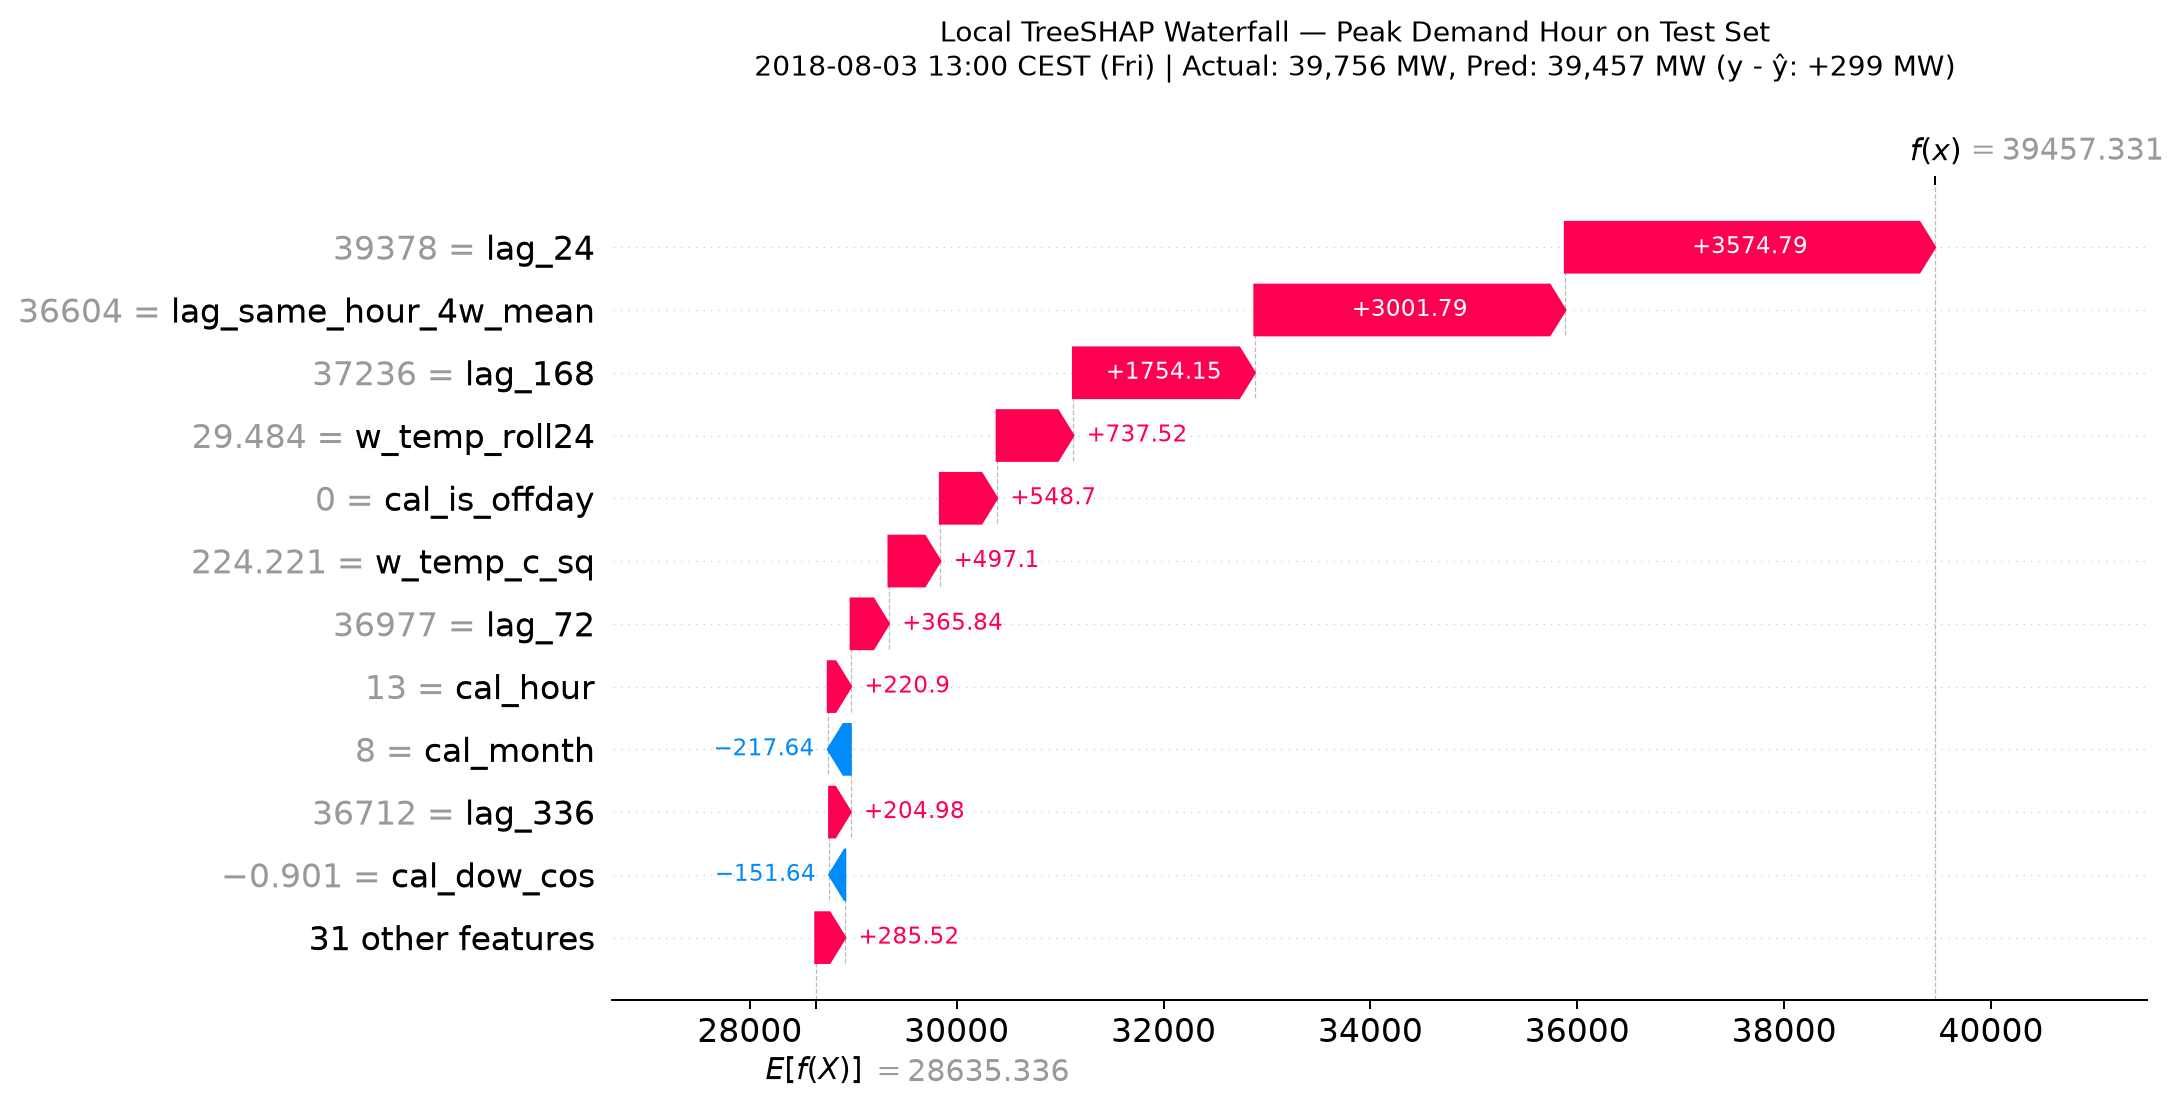

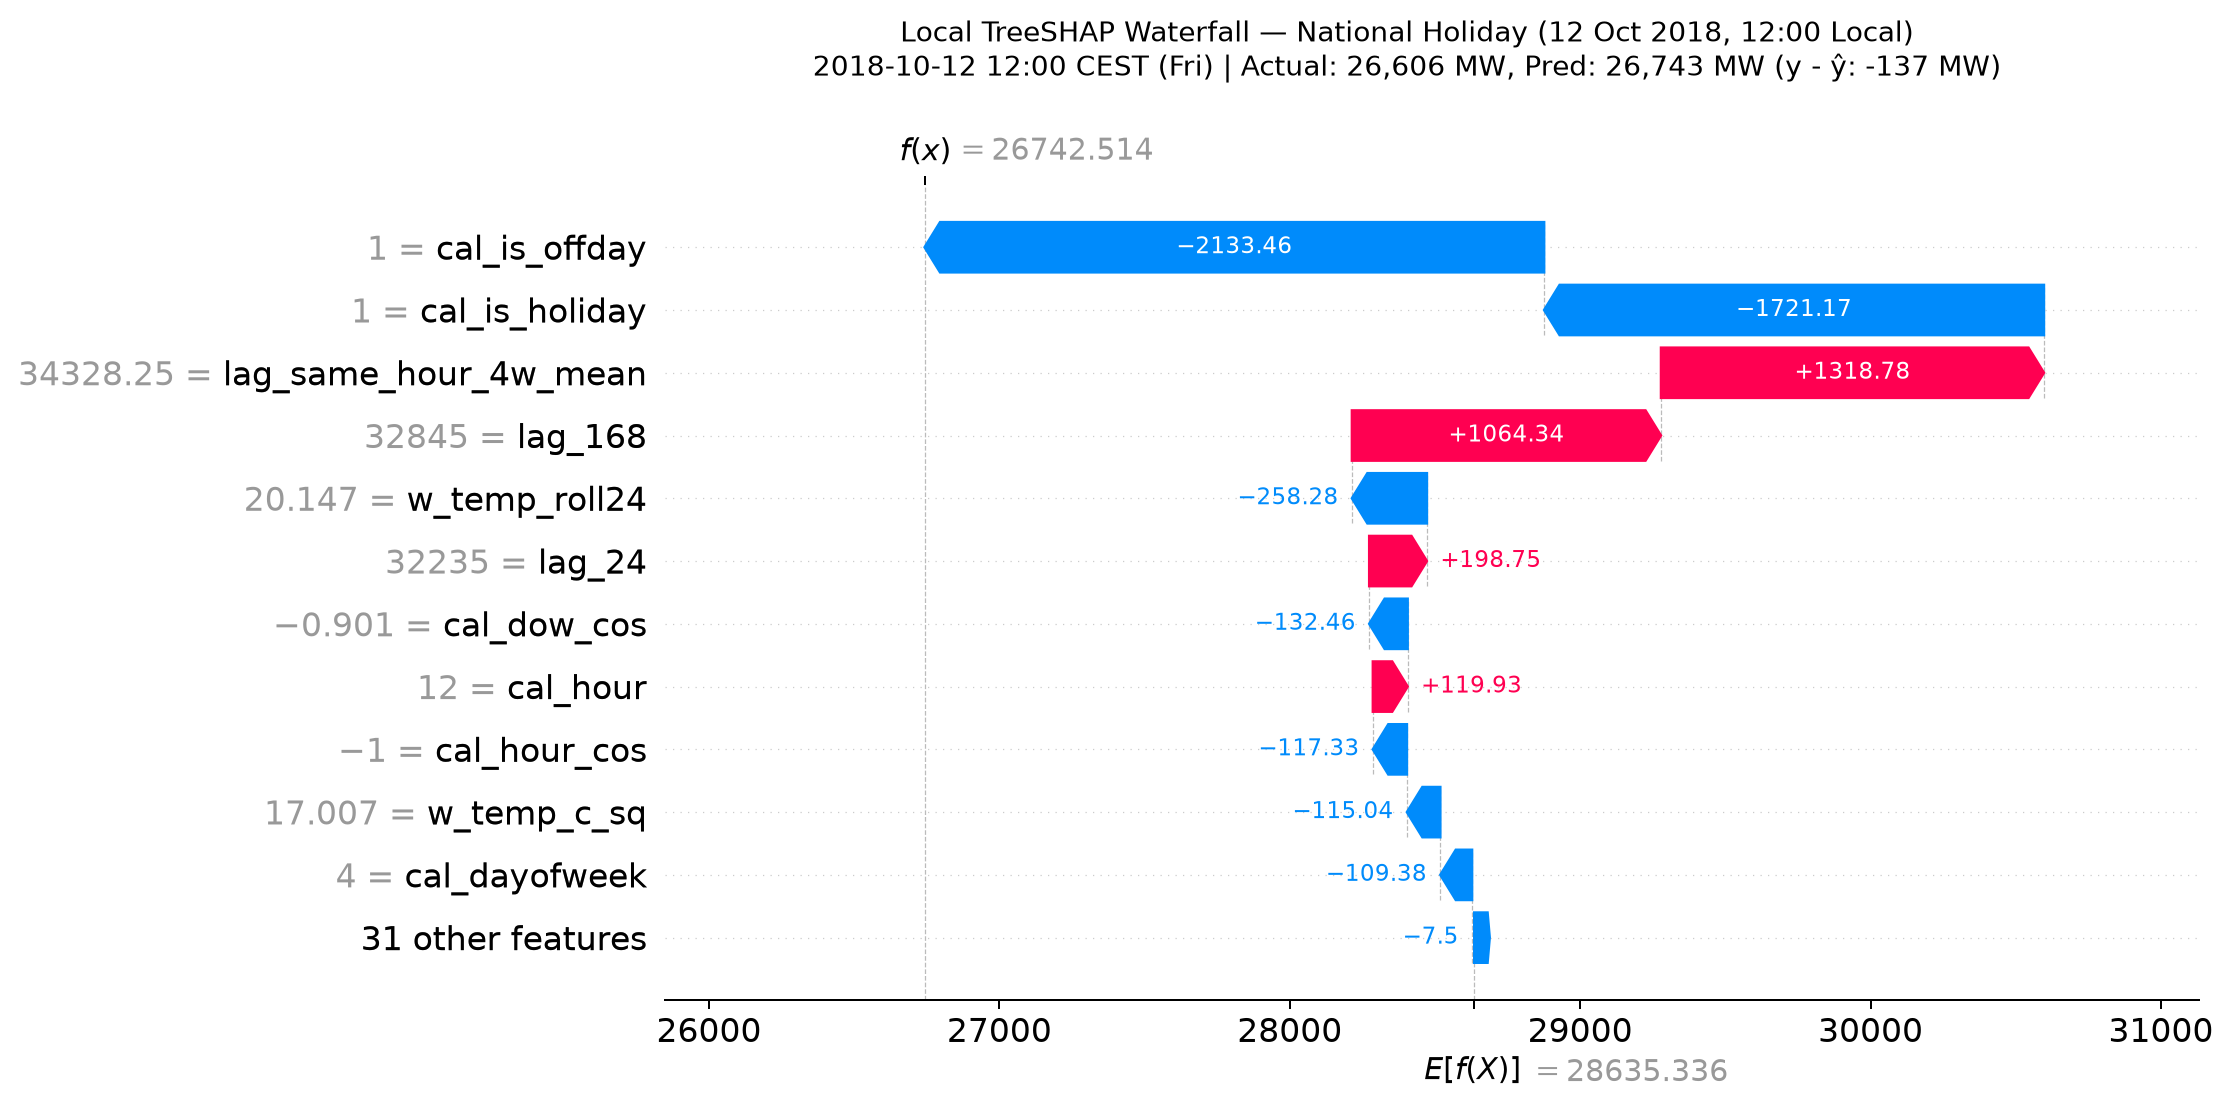

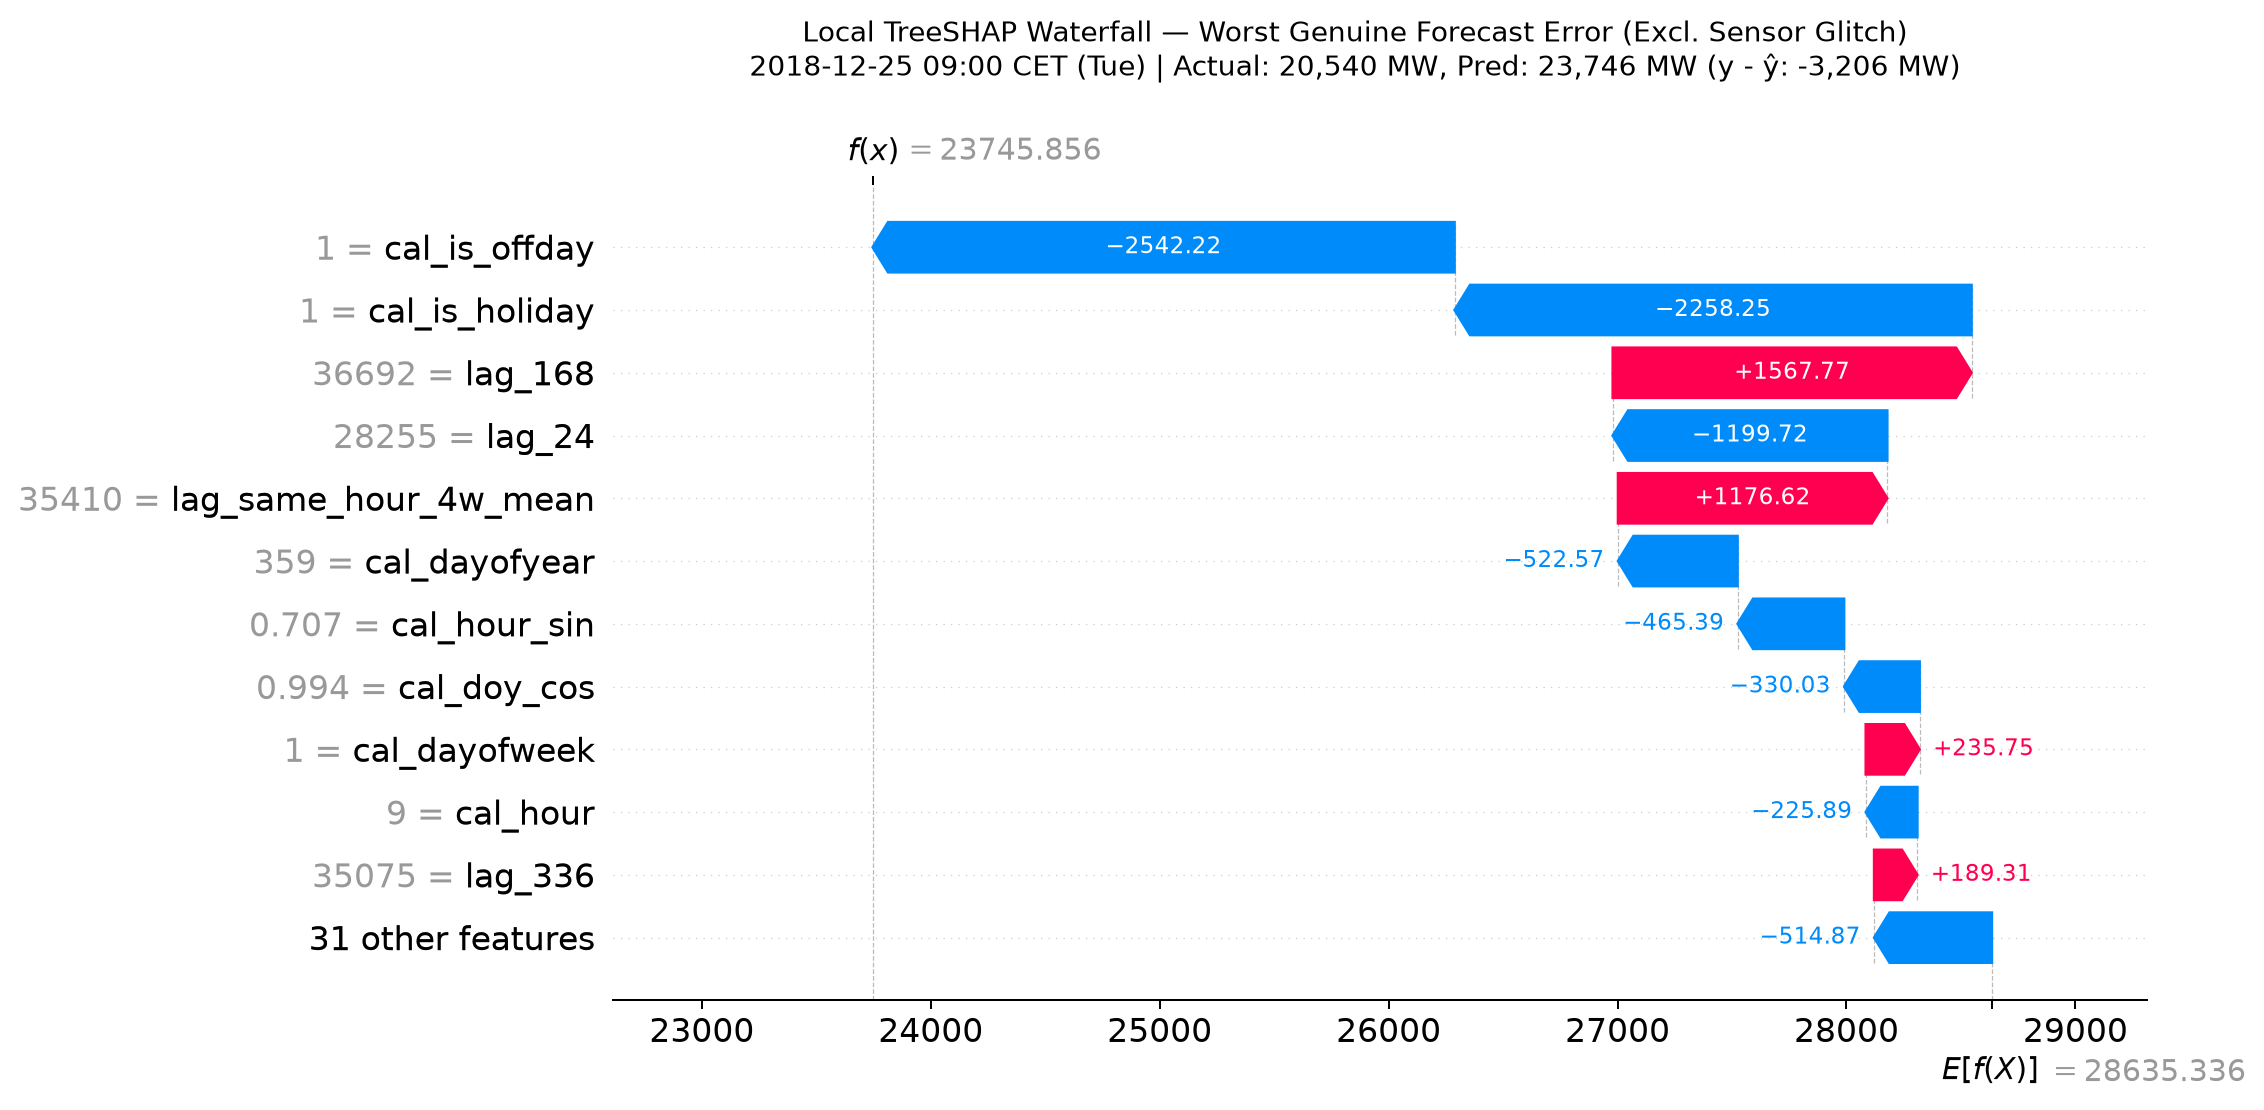

In [8]:
print("=== 4D. Các tình huống giải thích cục bộ trên tập Test (gồm ghi chú giờ gai cảm biến 05/06/2018) ===")
df_cases = pd.read_csv(RESULTS_DIR / "d_step4_local_cases.csv")
display(df_cases[["case", "local_time", "actual_mw", "pred_mw", "residual_y_minus_yhat_mw", "top_5_shap_drivers"]])

for tag in ["peak", "holiday", "worst_error"]:
    display(Image(filename=str(PLOT_DIR / f"d_step4_waterfall_{tag}.png"), width=860))

---
## Tóm tắt kết quả bàn giao (Phần D — Đồng bộ dữ liệu chuẩn `ff1758c`)

1. **Hiệu năng cuối trên `test` (`5.260` giờ, `horizon = 24h`, 42 đặc trưng)**:
   - **LightGBM (Tuned — $L_2$ + `categorical_feature`)**: **`MAE = 368,0 MW`** (**`-57,0 MW` / `-13,4%`** so với Random Forest `425,0 MW`), **`RMSE = 530,4 MW`** (`-15,6%` vs RF), **`MAPE = 1,286%`**, **`R² = 0,986`**, `ME = -69,1 MW`.
   - **XGBoost (Tuned — $L_2$)**: **`MAE = 371,3 MW`** (**`-53,7 MW` / `-12,6%`** vs RF), **`RMSE = 540,0 MW`**, **`MAPE = 1,298%`**, **`R² = 0,985`**, `ME = -78,3 MW`.
   - Độ ổn định 5 seeds rất chặt (`LightGBM: 369,85 ± 3,48 MW`, `XGBoost: 370,61 ± 3,09 MW`); ở chân trời **`h = 1h` (Validation)**, LightGBM (`182,5 MW`, `MAPE = 0,623%`) và XGBoost (`195,6 MW`) vượt sâu Random Forest (`257,5 MW`) lẫn TSO trên `val` (`309,4 MW`).
2. **Tệp bàn giao cho Người E (Mục 5 — So sánh & kiểm định thống kê)**:
   - `results/metrics_all.csv`, `results/predictions_test_all.parquet`, `results/mae_by_hour_all.csv`, `results/mae_by_dow_all.csv`, `results/horizon_comparison_all.csv`.
3. **Giải thích & phân tích lỗi (Mục 6 — Exact TreeSHAP)**:
   - Tiên đề cộng tính cục bộ khớp tuyệt đối (`3,20e-10 MW` trên `test`, `2,69e-10 MW` trên `val`); đồng thuận cao với RF Permutation trên cùng tập `val` (`Spearman = 0,820`, Top 4 biến trùng nhau hoàn toàn).
   - Cộng gộp 3 họ đặc trưng: **Lag / Rolling `73,7%`**, **Calendar `20,4%`**, **Weather `5,9%`**; đường cong chữ U nhiệt độ sắc nét quanh `18°C–22°C` (tăng tới `+1.900 MW` khi nắng nóng đỉnh điểm).
   - Ba tình huống cục bộ: đỉnh hè `2018-08-03 13:00` sai chỉ `+299 MW` (`<0,8%`), Quốc khánh `2018-10-12 12:00` sai chỉ `-137 MW` (`0,5%`), và sai số thực lớn nhất (loại trừ gai cảm biến `05/06`) là sáng Giáng Sinh `2018-12-25 09:00` (`-3.206 MW`) do cờ nhị phân `cal_is_holiday` chưa phân biệt mức giảm cực sâu riêng của Giáng Sinh.